# 第一部分：原论文行为复现与历史 HDDM 探索

[本部分 README](README_zh.md) · [第二部分](../02_reanalysis_2026/02_reanalysis_2026.ipynb)

## 研究问题与方法

先问 Good-self 行为优势是否能在公开数据和既有处理口径下复现，再问历史 HDDM 能支持多强的解释。本 Notebook 只读取已有表图，不重新分析原始数据、不运行 MCMC。Pilot 29 人；Confirm Matching 42 人、Categorization 41 人。图表保持历史样本/筛选口径。

## 诊断发现与方法调整

15 个选定 t 统计在预设容差内重现，并非所有论文统计都等价。Pilot Categorization RT 的条件列设置、omega/Bayes-factor 定义与 ex-Gaussian bootstrap 次数有差异，详见 README。历史模型与新 H0–H3 不同，不能直接比较其系数或诊断门槛。

## 阅读顺序

研究问题与复现口径 → 选定行为结果（图 I-1–I-5）→ 原论文 HDDM（图 I-6）→ 历史 M0–M4 方法、诊断与预测（图 I-7–I-10）→ 限制与第二部分的问题。M0–M4 是历史候选模型编号，不是 H0–H3 的别名。


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / '01_reproduction_2020').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the hu2020-ddm repository.')
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 32)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
def table(path):
    return pd.read_csv(ROOT / path)
def show(path, width=1000):
    display(Image(filename=str(ROOT / path), width=width))


## 结果：选定行为统计复核

In [2]:
checks = pd.concat([table('01_reproduction_2020/Output/behavior/'+s+'/'+s+'_key_reproduction_checks.csv').assign(study=s) for s in ['pilot','confirm']], ignore_index=True)
assert len(checks)==15 and checks.within_target_tolerance.all()
display(checks)

,outcome,contrast,paper_t,reproduced_t,abs_difference,within_target_tolerance,study
0,match_RT,GS_BS,-5.66900,-5.66944,0.00044,True,pilot
1,match_RT,GO_BO,-3.16400,-3.16370,0.00030,True,pilot
2,match_d,GS_BS,3.26000,3.26049,0.00049,True,pilot
3,categ_RT,GS_BS,-3.00000,-3.00456,0.00456,True,pilot
4,categ_ACC,GS_BS,3.59100,3.59075,0.00025,True,pilot
5,categ_ACC,GS_GO,3.43000,3.43222,0.00222,True,pilot
6,match_RT,GS_BS,-8.42000,-8.42343,0.00343,True,confirm
7,match_RT,GO_BO,-2.37000,-2.37541,0.00541,True,confirm
8,match_RT,GS_GO,-3.34000,-3.33717,0.00283,True,confirm
9,match_d,GS_BS,4.30000,4.30365,0.00365,True,confirm


### 图 I-1｜Pilot Matching：正确 RT 与历史 d′

Good-self 行为优势是待解释现象；历史 d′ 对非反应和极端比率的处理不同于第二部分合法选择口径。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

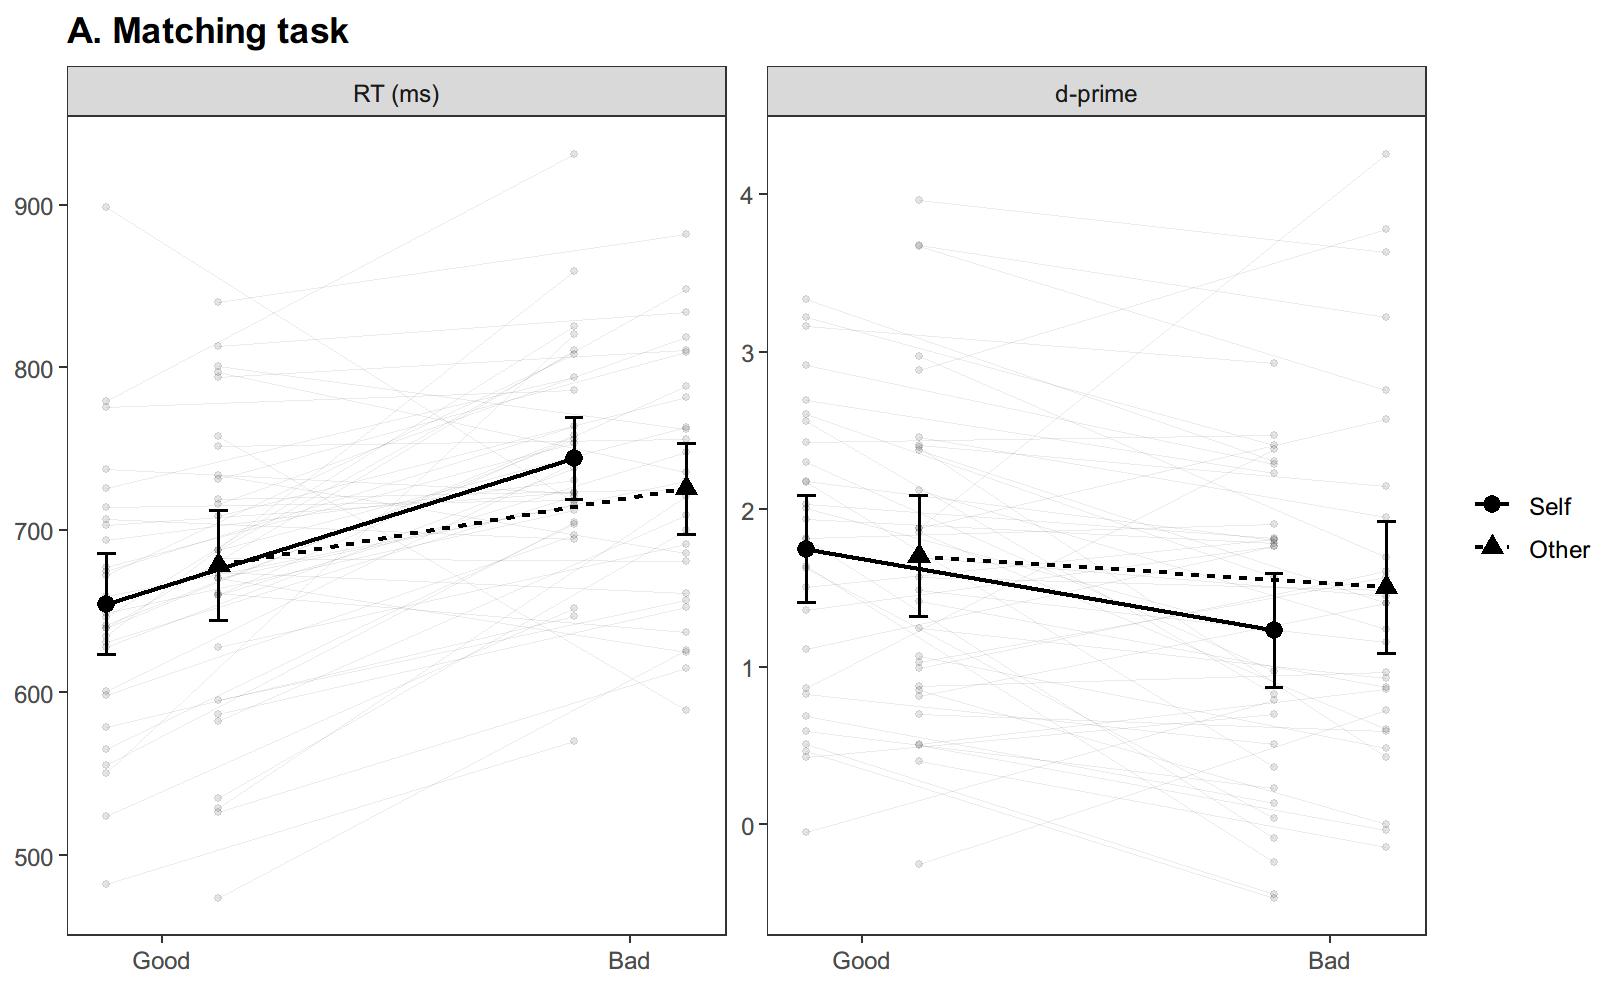

In [3]:
show('01_reproduction_2020/Output/behavior/pilot/figures/pilot_matching_behavior.png')

### 图 I-2｜Pilot Categorization

该图展示既有处理下的行为，不消除条件列分配引起的 ANOVA 可比性限制。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

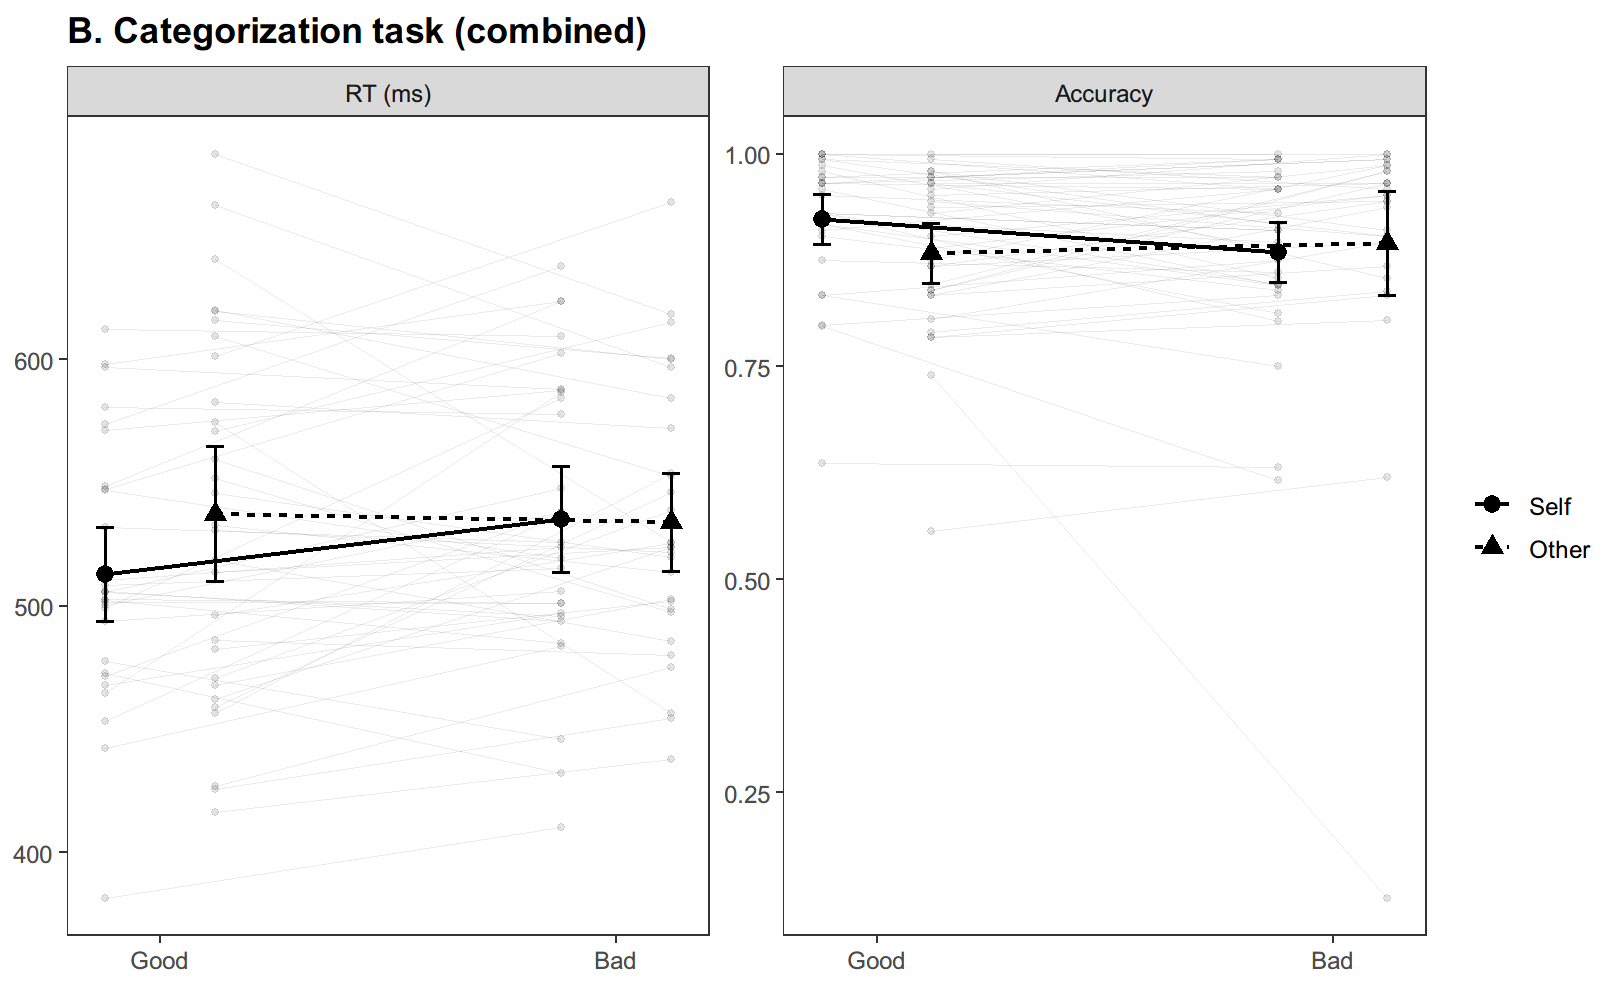

In [4]:
show('01_reproduction_2020/Output/behavior/pilot/figures/pilot_categorization_behavior.png')

### 图 I-3｜Confirm Matching

原行为筛选规则下的正确 RT 和 d′；不是全事件观察模型的预测图。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

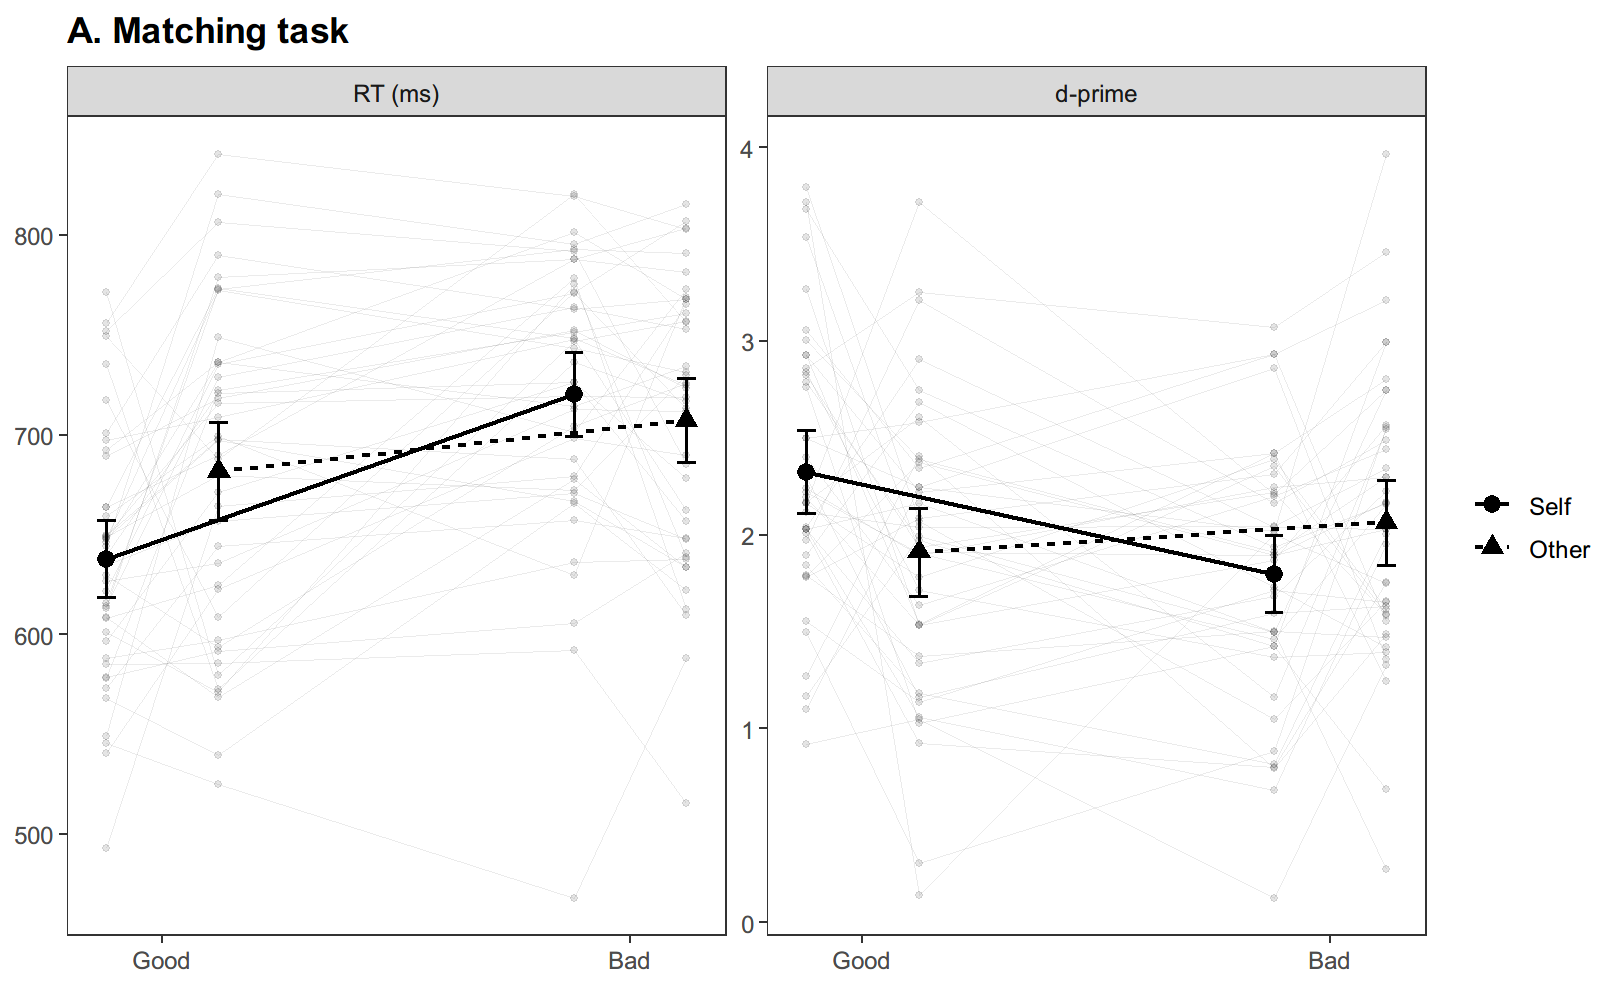

In [5]:
show('01_reproduction_2020/Output/behavior/confirm/figures/confirm_matching_behavior.png')

### 图 I-4｜Confirm Identity

Identity 行为结果与其 HDDM 是否收敛是不同问题。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

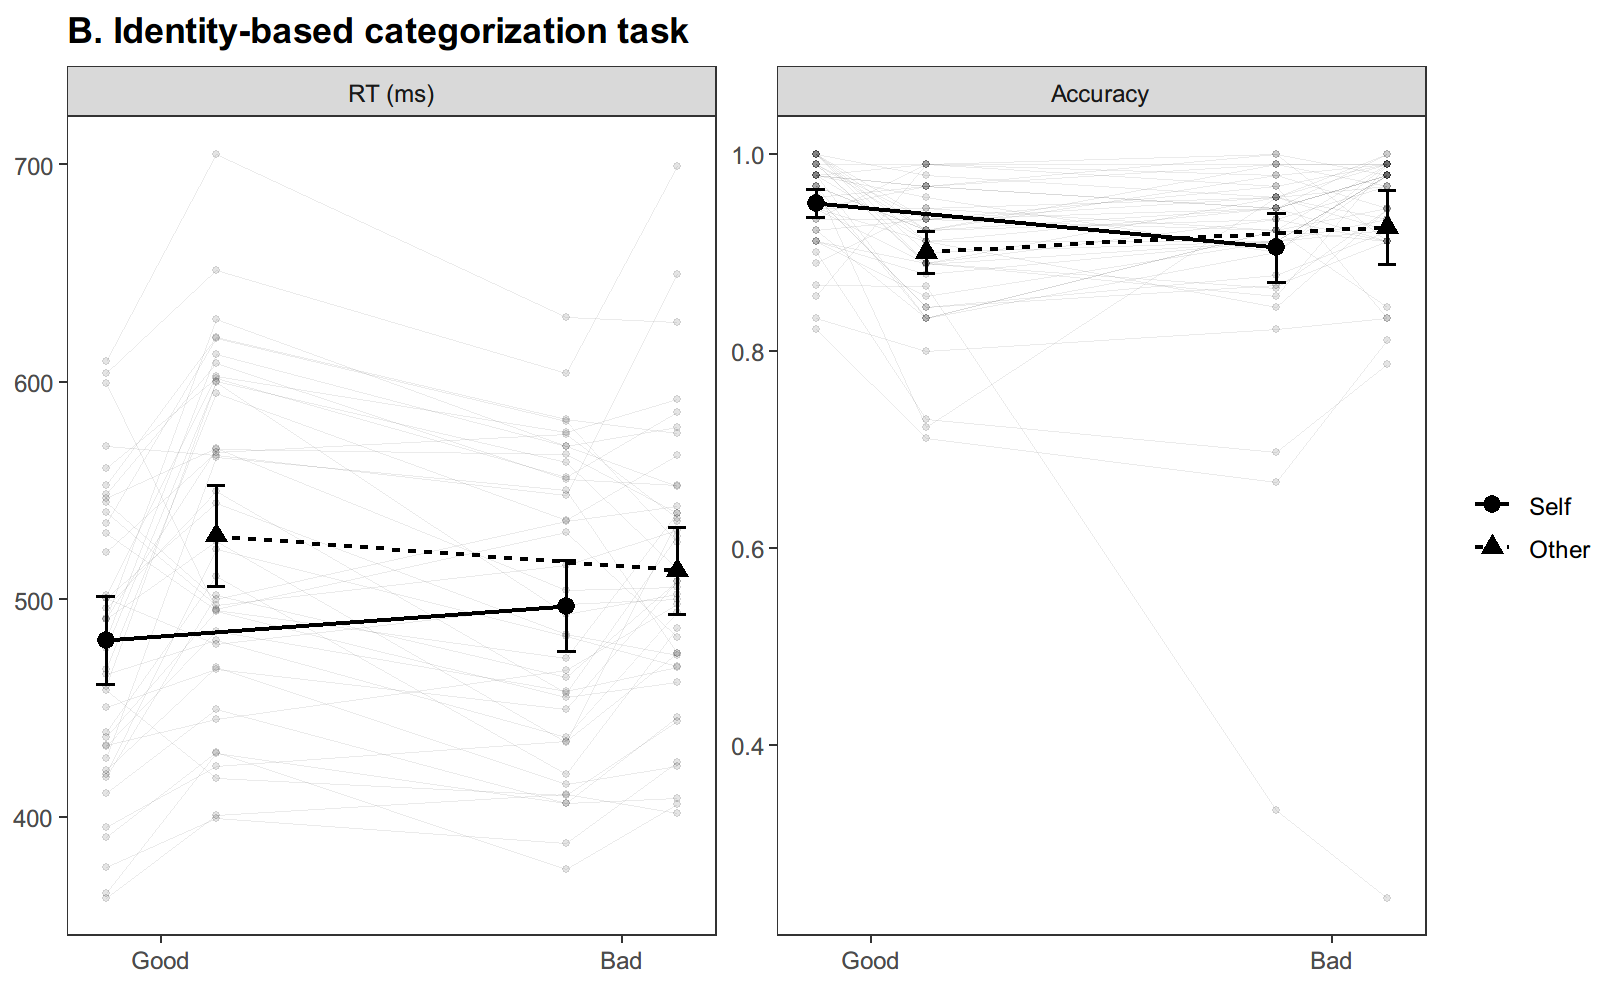

In [6]:
show('01_reproduction_2020/Output/behavior/confirm/figures/confirm_identity_behavior.png')

### 图 I-5｜Confirm Valence

历史 Figure 3C 引用已校正为 Valence 数据；不能从图形一致推断所有统计完全一致。

行为误差条为均值 ±1.96 SE，不是后验区间；原图与筛选定义见 README。

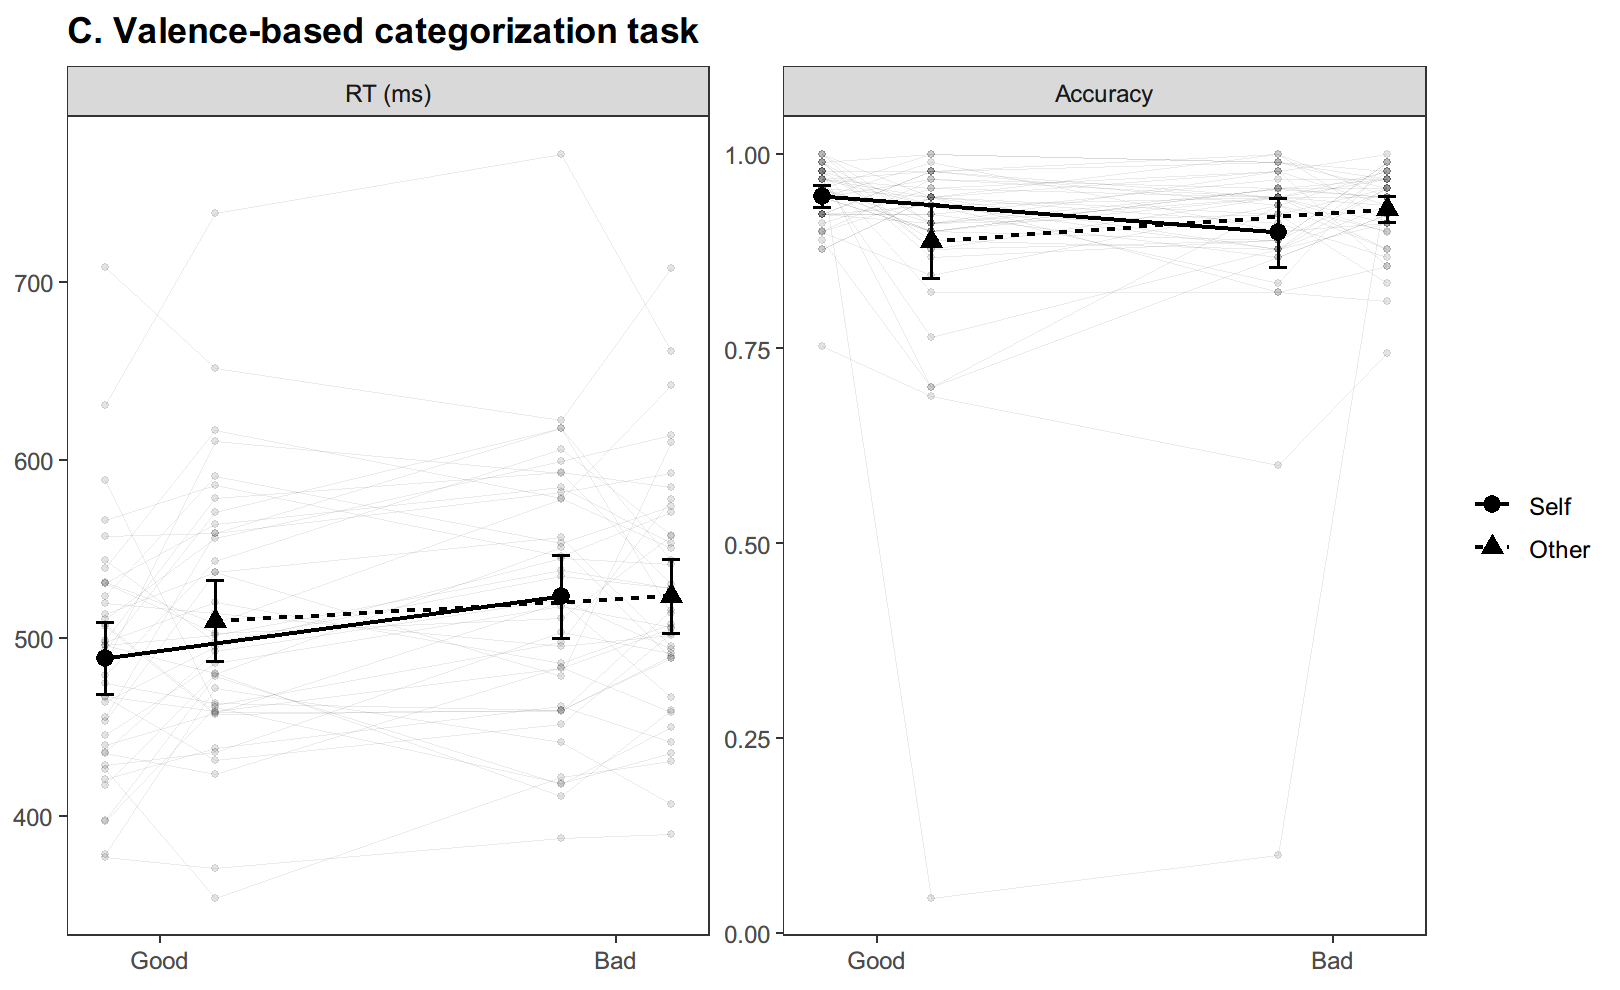

In [7]:
show('01_reproduction_2020/Output/behavior/confirm/figures/confirm_valence_behavior.png')

### 图 I-6｜历史 HDDM：原 Figure 4 漂移结果

使用已分发 r01 的 35 个群体参数，每个 9,000 样本；不是四链合并后验，不能代替完整数据库的诊断或 PPC。

模型标签 vtz/p0/r01 原样保留。此图展示漂移参数的后验密度曲线，不是误差条或可信区间图。

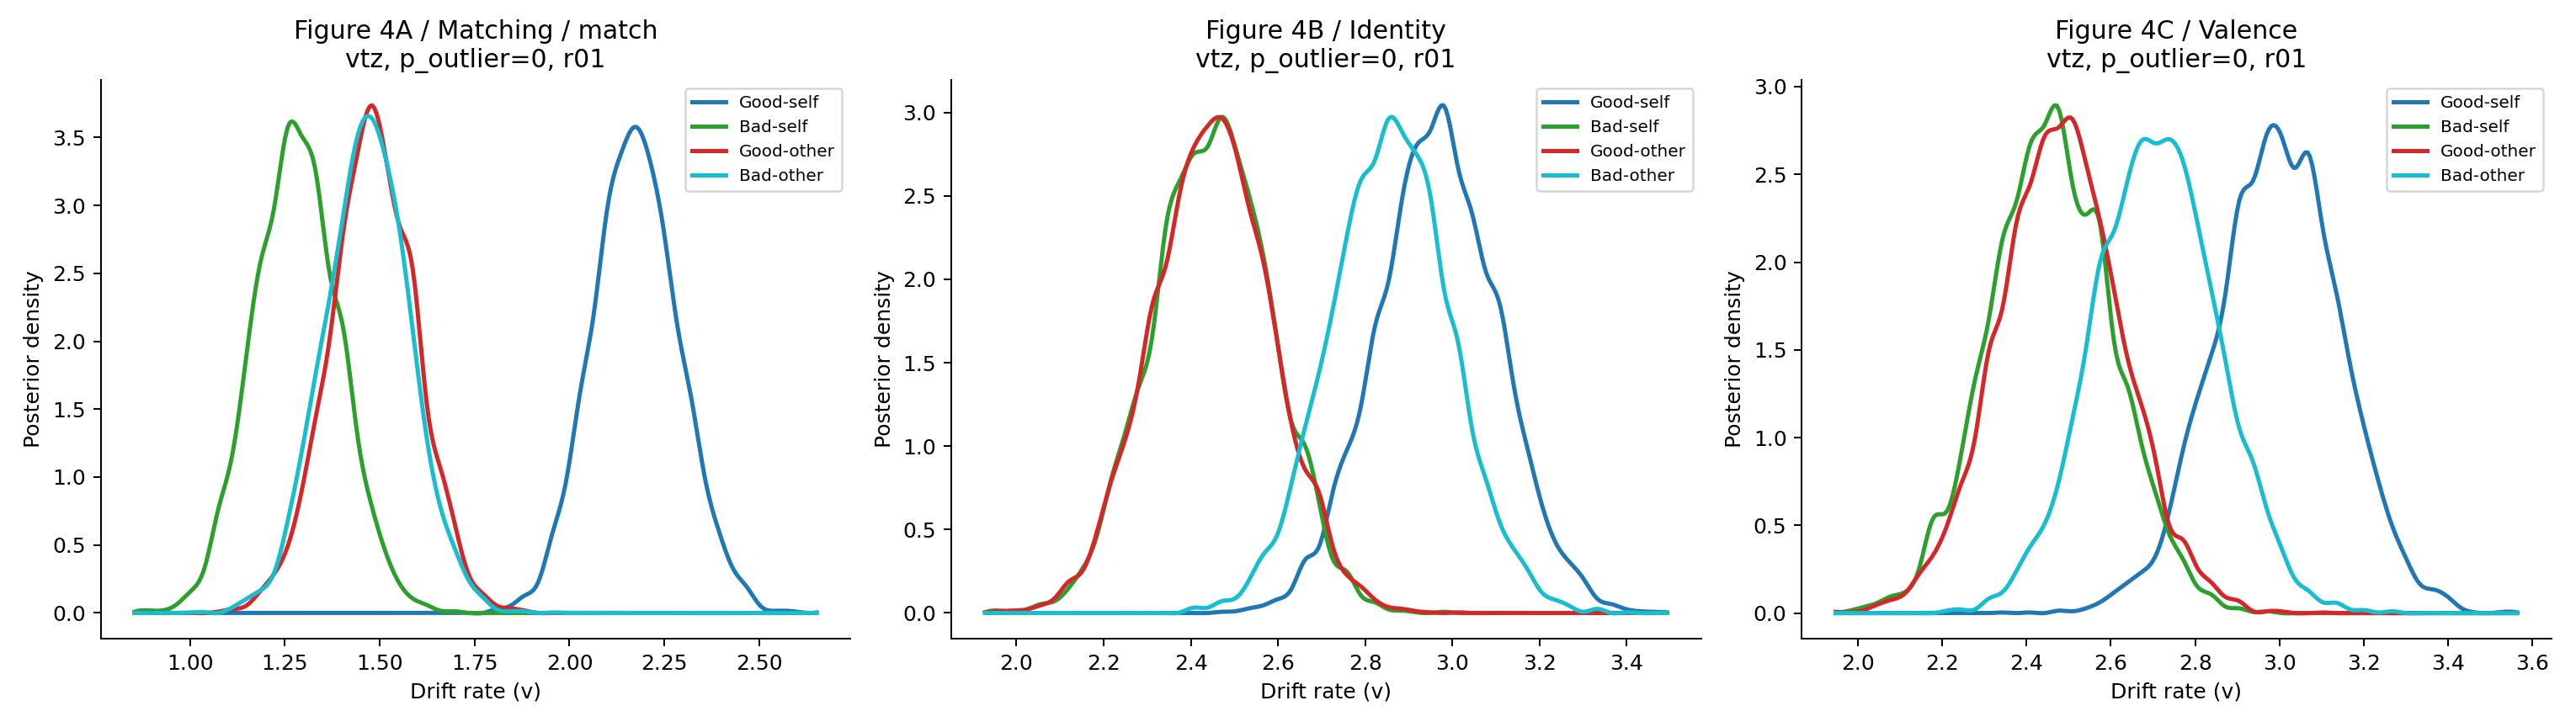

In [8]:
show('01_reproduction_2020/Output/figures/figure04_vtz_p0_r01_drift.png')

## 原论文 HDDM 与补充复现的完成边界

Matching/Identity/Valence vtz p0 和 Identity vz p0 通过当时配置门槛；Identity vz p0.05 未通过，不合并其运行。Matching/Valence vz 只有一次运行，属描述性结果。这些是原论文模型的复现状态，与下面 M0–M4 扩展的收敛结果分开报告。

15 项选定 t 统计在既定容差内复现；33 个可比 ANOVA F 值差异小于 1e-9。Pilot Categorization RT 的7项比较因条件列配置不同不具可比性，不能说全部统计复现。

ex-Gaussian 完成231个单元、27名被试符合后续条件；一个仅3试次的单元未拟合。采用1,000次 bootstrap，原文为2,000次；与可用作者估计相比，mu/sigma/tau 最大差约 .0283/.0567/.0208 秒。详见[参数表](Output/behavior/pilot/exgaussian/parameters_all.csv)。补充贝叶斯/简单效应分析、Figure S3及完整Table S2/S3仍未完成。


## 历史 M0–M4 HDDM 探索：从复现到第二部分的问题

以下完整保留历史模型的方法、诊断和图表，属于第一部分方法背景，不是H0–H3当前结果。

以下保留历史模型的分析口径；其中窗口、预测和恢复的不足，是进入第二部分观察模型再分析的原因。该阶段的“未完成”不替代第二部分的当前状态。


### 历史探索 1. 数据与模型

实验条件由身份（Self、Other）和道德属性（Good、Bad）组合而成。Matching判断形状与标签是否匹配；Identity和Valence分别要求按身份和道德属性分类。

|变量|数据字段|含义|
|---|---|---|
|身份|id|Self、Other|
|道德属性|val|Good、Bad|
|匹配性|match、stim|Matching的match/mismatch，对应stim=1/0|
|反应时|rt|秒|
|选择|response|上边界依次为Match、Self、Good|
|准确性|accuracy|反应是否正确，与选择编码区分|

Matching纳入42人、24527试次，排除一个非法按键；Identity和Valence各纳入41人，分别为14493和14431试次。主分析保留正RT；RT≤0.2秒的试次数列于下表。

In [9]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'01_reproduction_2020').is_dir())
ROOT = REPO/'02_reanalysis_2026'
OUT = ROOT / 'Output'
def read_json(relative):
    return json.loads((OUT / relative).read_text(encoding='utf-8-sig'))
def read_table(relative):
    return pd.read_csv(OUT / relative)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 25)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
audit = read_json('data_audit.json')
display(pd.DataFrame({task: {k: row[k] for k in ['subjects','original_rows','fit_rows','rt_le_0p2']} for task,row in audit.items()}).T)


,subjects,original_rows,fit_rows,rt_le_0p2
matching,42,24528,24527,28
identity,41,14493,14493,29
valence,41,14431,14431,12


### 拟合参数下的模拟决策路径

**图 I-7. Matching M4 的拟合参数模拟路径与有效漂移。** A：使用 Good-self 条件的群体后验均值固定参数（$a=1.224$、$z=0.568$、$t=0.464$ 秒、$v=2.214$、$dc=0.321$），分别模拟 Match、Mismatch 刺激的前两条路径，不按结局或外观筛选。路径从 $\bar a\bar z$ 出发，首次触及边界时停止；它们不是实测证据轨迹，也不代表某位被试。图中时间从积累开始计，反应时另加非决策时间 $t$。B：四种关联条件的有效漂移 $+v+dc$ 与 $-v+dc$，点为后验均值，线为 95% 等尾可信区间；区间由四条链中配对的 $v$、$dc$ 样本计算。

路径使用单位扩散噪声的 Wiener 过程，以 Euler–Maruyama 步进（$\Delta t=0.0001$ 秒，种子 `2026102301`）近似模拟，并在最后一个时间步内插值确定边界接触。A 图不传播参数的后验不确定性或个体差异，仅展示 DDM 主体，不包含离群混合成分或实验反应窗口，因此不是完整的后验预测检验。$\bar a\bar z$ 是代入均值后的起点，不等于 $E[az]$。原有 PPC 与参数恢复限制仍适用。

下图和汇总表读取已保存的结果，不重新拟合模型。生成图的命令为 `python Scripts/hddm/matching/matching_plot.py --kind schematic --output Output`。
上述命令须从仓库的 `02_reanalysis_2026/` 目录运行。


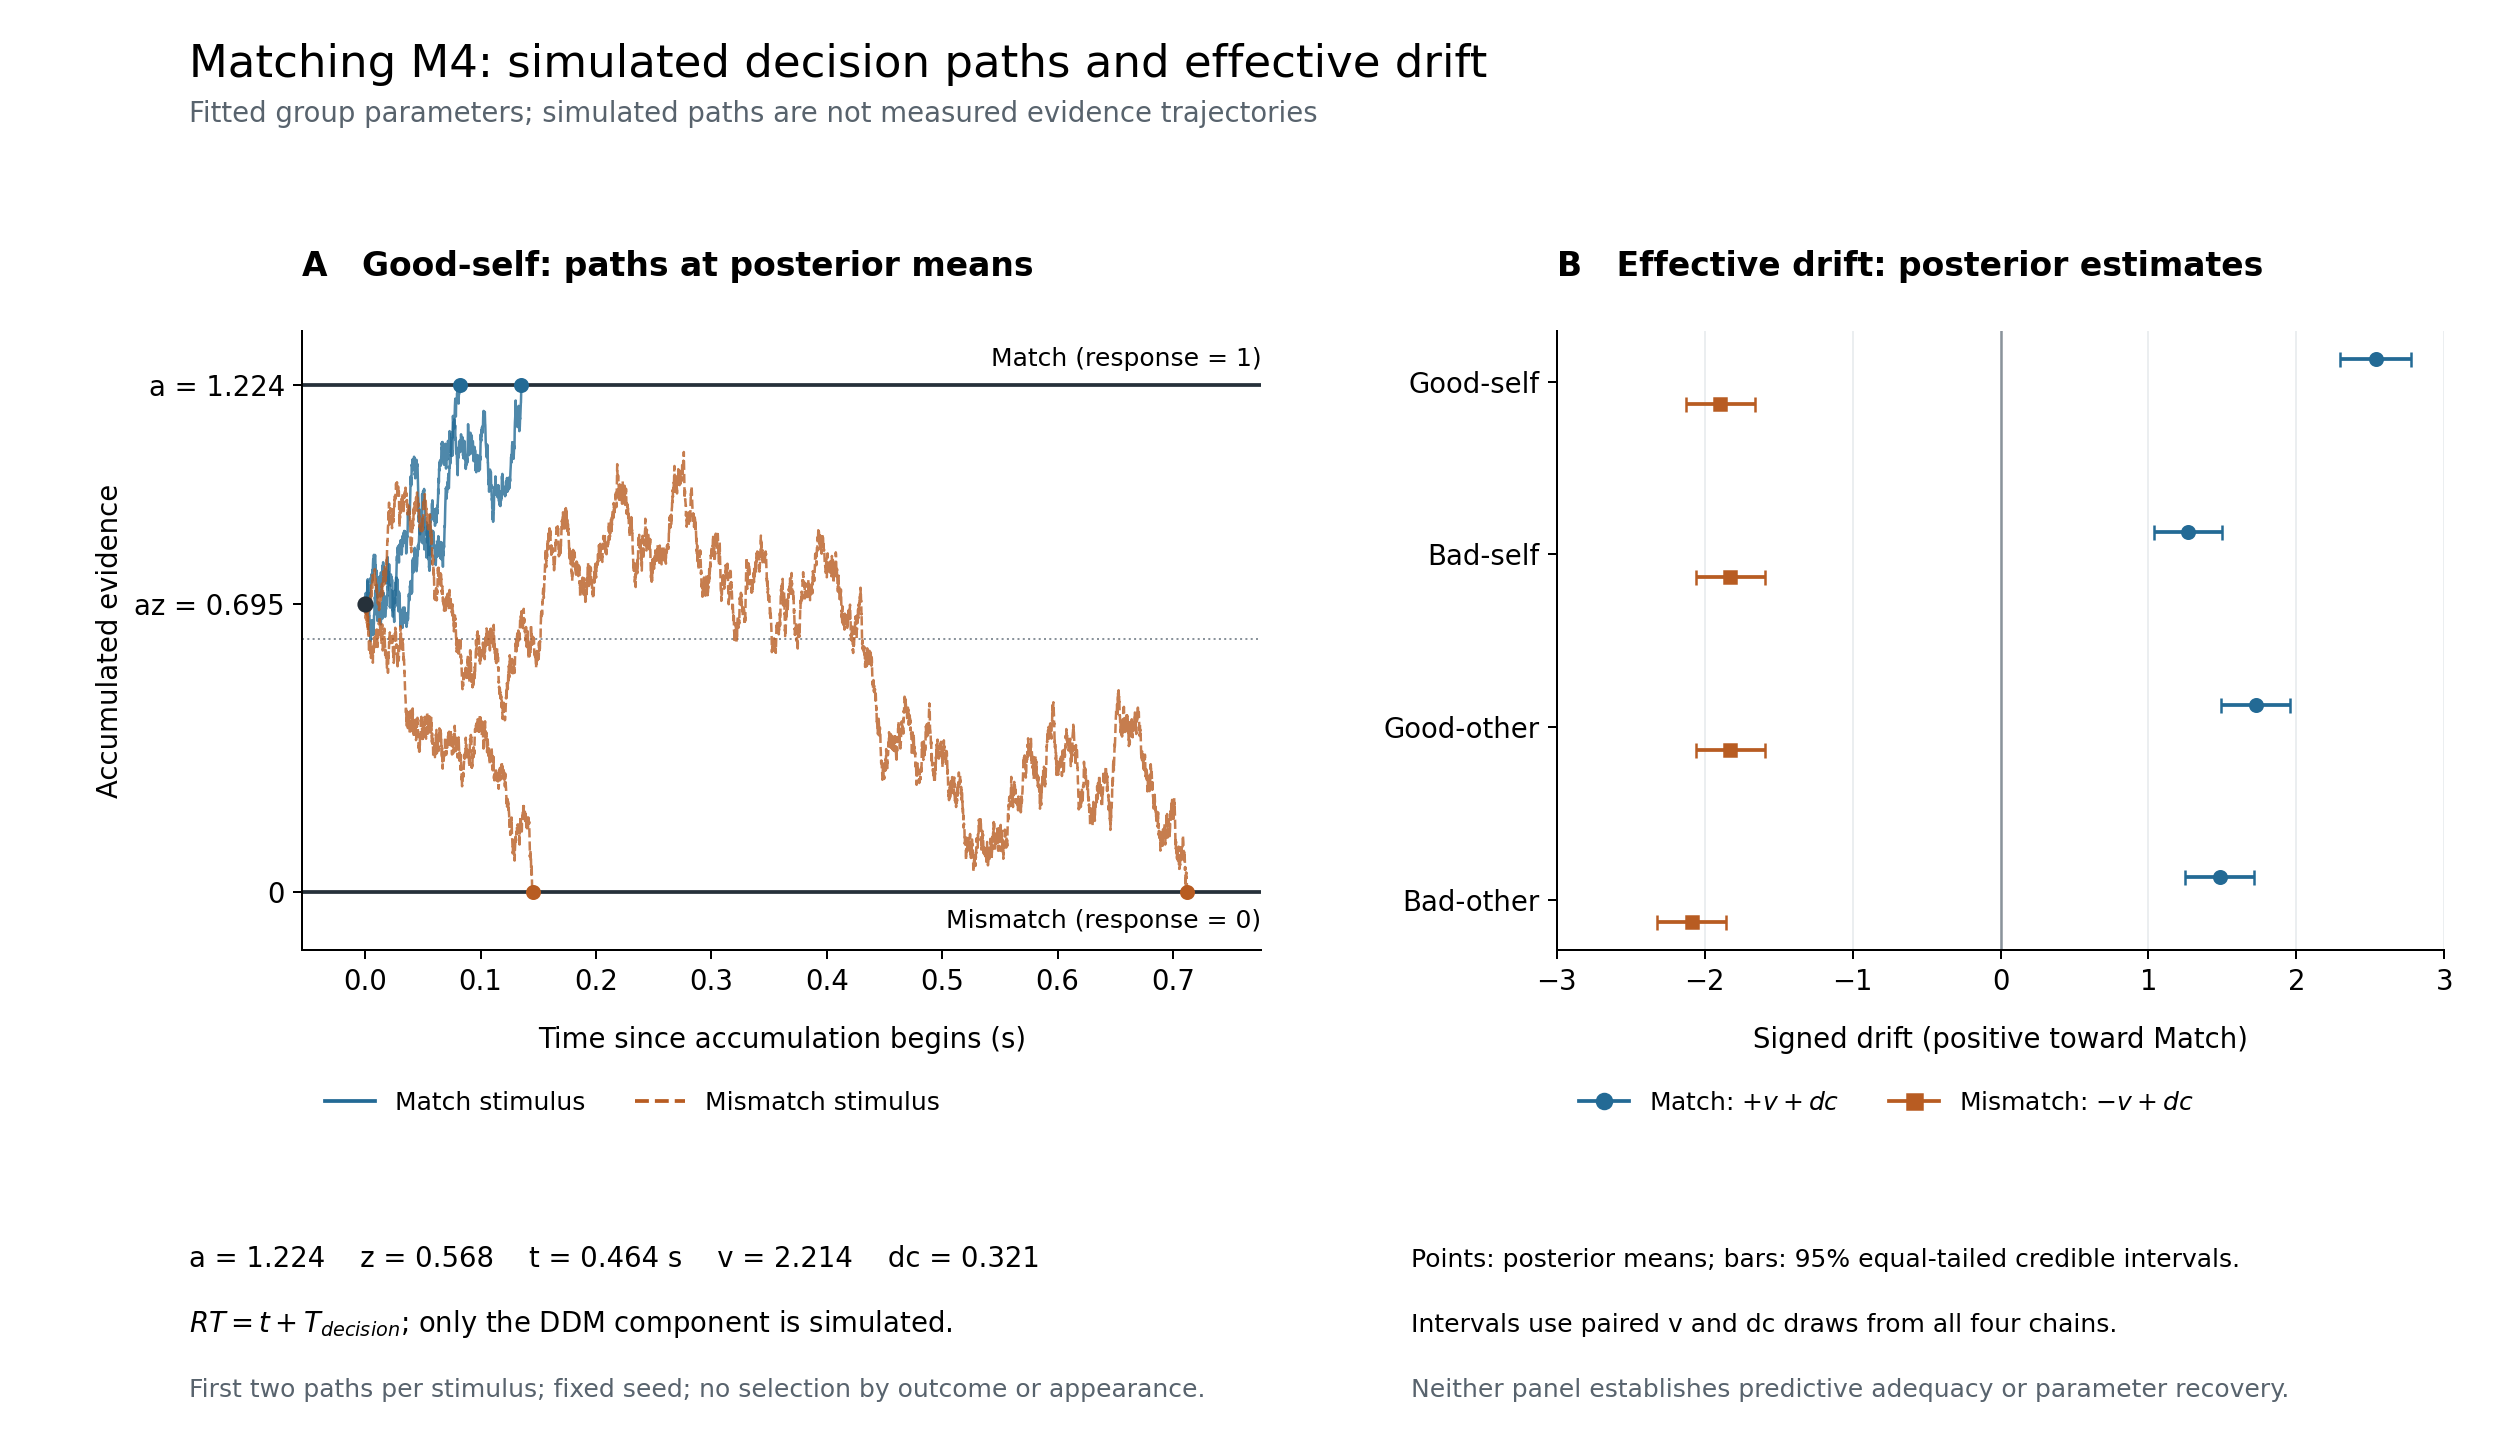

,condition,stim,mean,q025,q975
0,Self.Good,1,2.5355,2.2972,2.7753
1,Self.Good,0,-1.8928,-2.1276,-1.6598
2,Self.Bad,1,1.2690,1.0369,1.4973
3,Self.Bad,0,-1.8267,-2.0586,-1.5925
4,Other.Good,1,1.7238,1.4926,1.9567
5,Other.Good,0,-1.8283,-2.0582,-1.5931
6,Other.Bad,1,1.4823,1.2500,1.7130
7,Other.Bad,0,-2.0876,-2.3194,-1.8562


In [10]:
display(Image(filename=str(OUT / 'hddm/matching/figures/matching_ddm_schematic.png'), width=1100))
effective_drift = read_table('hddm/matching/m4/final/diagnostics/matching_effective_drift.csv')
display(effective_drift[['condition','stim','mean','q025','q975']])

正漂移指向 Match，负漂移指向 Mismatch；负值越小，表示越强地朝 Mismatch 积累。单个条件的可信区间不能替代条件差异的后验检验。路径参数与生成设置见 `../02_reanalysis_2026/Output/hddm/matching/figures/matching_ddm_simulation.json`。

### 历史探索 2. 模型比较

五个模型分别估计不同形式的起点偏置z与漂移偏置dc。

|模型|z|dc|
|---|---|---|
|M0|0.5|0|
|M1|估计，跨条件共享|0|
|M2|0.5|估计，跨条件共享|
|M3|估计，跨条件共享|估计，跨条件共享|
|M4|估计，跨条件共享|随条件变化|

所有模型分层估计边界间距a、非决策时间t和漂移率v。a、t跨条件共享；Matching的v随身份×道德属性变化，Identity随道德属性变化，Valence随身份变化。M4的dc使用相同条件划分。

每个模型的初筛链迭代10000次、舍弃前5000次。下表汇总DIC、有效样本量和预测误差。DIC用于同一任务内的相对比较；单链初筛无法充分评价收敛性。各任务选择M4继续进行四链评估，模型选择仍有不确定性。

In [11]:
comparison = pd.concat([read_table(f'hddm/{task}/model_comparison.csv') for task in audit], ignore_index=True)
assert len(comparison) == 15
columns = ['task','model','dic','ess_bulk_min','ess_tail_min','choice_rmse','rt_median_rmse_seconds','provisional_selected']
display(comparison[columns])

,task,model,dic,ess_bulk_min,ess_tail_min,choice_rmse,rt_median_rmse_seconds,provisional_selected
0,matching,m0,-1559.3040,300.8249,236.8832,0.0962,0.0452,False
1,matching,m1,-2809.5157,271.2934,384.7130,0.0899,0.0428,False
2,matching,m2,-2075.7841,357.4918,150.7361,0.0863,0.0464,False
3,matching,m3,-2987.9888,222.1078,68.4176,0.0855,0.0472,False
4,matching,m4,-3647.2699,289.8146,151.1970,0.0719,0.0400,True
5,identity,m0,-13021.7048,17.4043,11.1448,0.0528,0.0367,False
6,identity,m1,-13613.6770,3.2761,28.1834,0.0541,0.0292,False
7,identity,m2,-13449.5112,8.0747,14.4816,0.0535,0.0321,False
8,identity,m3,-13644.5475,5.9028,25.5717,0.0538,0.0310,False
9,identity,m4,-14007.3199,21.1552,32.7063,0.0503,0.0261,True


### 历史探索 3. Matching的身份与道德属性差异

Good-self的漂移率高于Bad-self，也高于Good-other。下表为四条件的后验均值与95%等尾可信区间。

Matching与mismatching共享漂移率幅度，因此这些值概括两个刺激方向，不是仅匹配试次的独立估计。

In [12]:
estimates = read_table('hddm/matching/m4/final/diagnostics/matching_parameter_contrasts.csv')
condition_labels = {'v(Self.Good)':'Good-self（好自我）','v(Self.Bad)':'Bad-self（坏自我）','v(Other.Good)':'Good-other（好他人）','v(Other.Bad)':'Bad-other（坏他人）'}
condition_results = estimates.set_index('parameter').loc[list(condition_labels), ['mean','q025','q975']].copy()
condition_results.index = [condition_labels[x] for x in condition_results.index]
display(condition_results.rename(columns={'mean':'v均值','q025':'95%区间下限','q975':'95%区间上限'}))

,v均值,95%区间下限,95%区间上限
Good-self（好自我）,2.2142,2.0178,2.4142
Bad-self（坏自我）,1.5478,1.3527,1.7431
Good-other（好他人）,1.7761,1.5821,1.9715
Bad-other（坏他人）,1.7849,1.5885,1.9800


In [13]:
questions = {
 'v:Self.Good-Self.Bad':'自我条件的道德属性差：Good-self − Bad-self',
 'v:Self.Good-Other.Good':'Good条件的身份差：Good-self − Good-other',
 'v:Other.Good-Other.Bad':'他人条件的道德属性差：Good-other − Bad-other',
 'v:Self.Bad-Other.Bad':'Bad条件的身份差：Bad-self − Bad-other',
 'v:interaction':'交互：(Good-self − Bad-self) − (Good-other − Bad-other)'}
contrast_results = estimates.set_index('parameter').loc[list(questions), ['mean','q025','q975']].copy()
contrast_results.index = [questions[x] for x in contrast_results.index]
display(contrast_results.rename(columns={'mean':'v差值','q025':'95%区间下限','q975':'95%区间上限'}))

,v差值,95%区间下限,95%区间上限
自我条件的道德属性差：Good-self − Bad-self,0.6663,0.3875,0.9423
Good条件的身份差：Good-self − Good-other,0.4381,0.1601,0.7193
他人条件的道德属性差：Good-other − Bad-other,-0.0089,-0.2775,0.2667
Bad条件的身份差：Bad-self − Bad-other,-0.2371,-0.5123,0.0435
交互：(Good-self − Bad-self) − (Good-other − Bad-other),0.6752,0.2845,1.0585


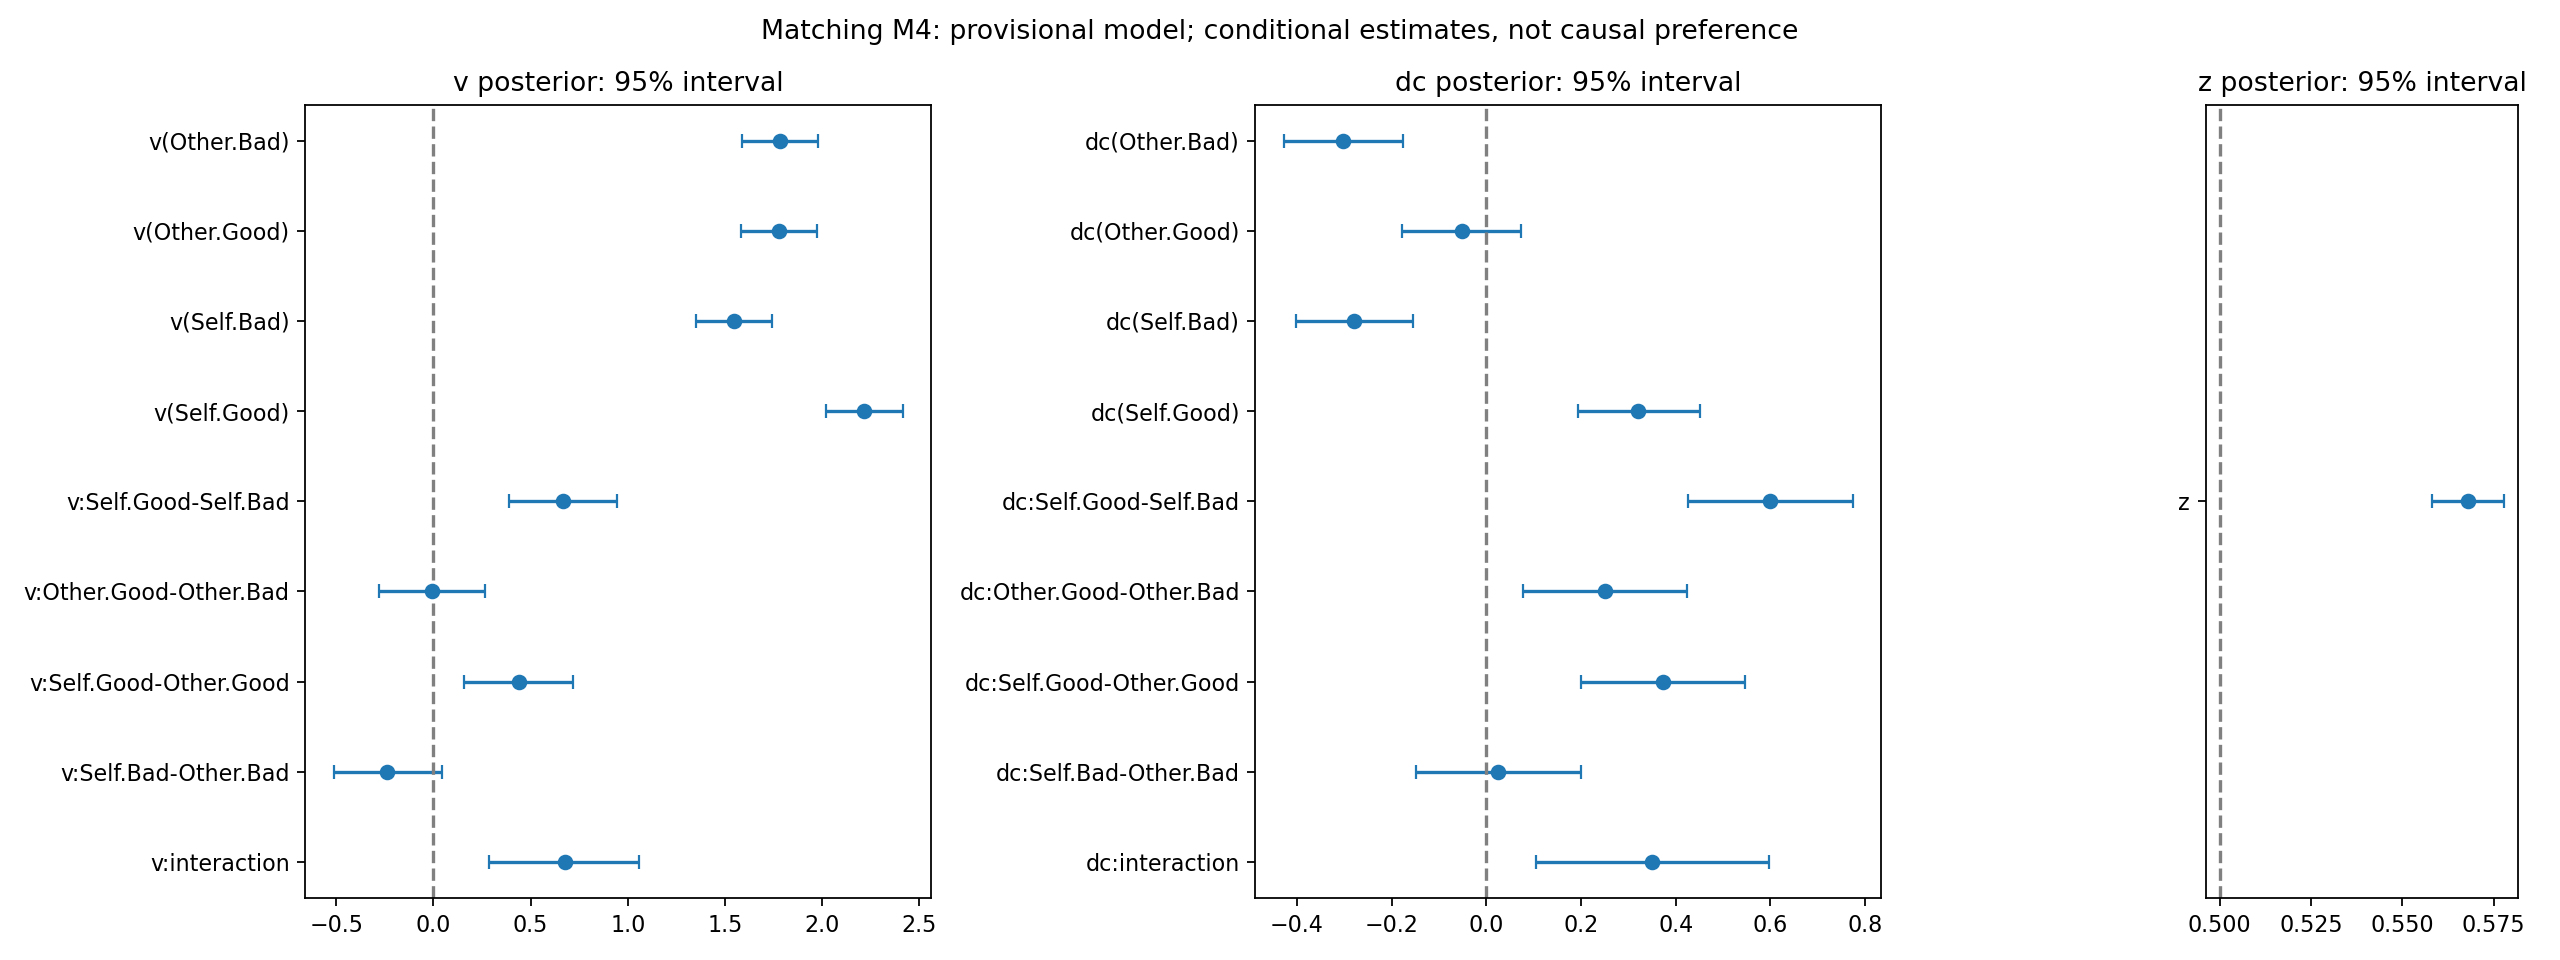

In [14]:
display(Image(filename=str(OUT / 'hddm/matching/figures/matching_m4_parameter_contrasts.png'), width=950))

**图 I-8. Matching的参数估计与条件对比。** 点为后验均值，线段为95%可信区间。v表示证据积累速度，dc表示漂移偏置，z表示相对起点。

Good-self相对Bad-self的v差为0.666，[0.387, 0.942]；相对Good-other的差为0.438，[0.160, 0.719]。他人条件的Good−Bad差为−0.009，[−0.278, 0.267]，区间包含0。

身份×道德属性的交互为0.675，[0.284, 1.059]：自我条件中的Good−Bad差异大于他人条件。该交互是后验参数的差中差。

起点z为0.568，[0.558, 0.578]，表明存在朝向“匹配”反应的起点偏置。Good-self与Bad-self的dc差为0.600，[0.427, 0.774]。两类偏置描述匹配判断中的反应倾向，不能直接等同于对“好自我”的偏好。

### 历史探索 4. 估计稳定性

Matching的四条链得到接近的参数分布，收敛检查通过。Identity与Valence各采用四条全新长链重估，每链60000次迭代、舍弃前30000次，仍有明显链间差异。

Rhat用于检查不同链的一致性，ESS表示采样包含的有效信息量。判断标准为Rhat<1.01、bulk/tail ESS均≥400，并结合轨迹检查。

In [15]:
main = read_json('hddm/matching/m4/final/diagnostics/matching_review.json')
rows = [dict(task='matching',sampling='10000/5000',max_rhat=main['max_rhat'],min_bulk_ess=main['min_bulk_ess'],min_tail_ess=main['min_tail_ess'],diagnostics_pass=main['diagnostics_pass'])]
for task in ['identity','valence']:
    review = read_json(f'hddm/{task}/m4/long_refit/diagnostics/review.json')[task]
    rows.append(dict(task=task,sampling='60000/30000',max_rhat=review['max_rhat'],min_bulk_ess=review['min_bulk_ess'],min_tail_ess=review['min_tail_ess'],diagnostics_pass=review['failed_parameters']==0))
display(pd.DataFrame(rows))

,task,sampling,max_rhat,min_bulk_ess,min_tail_ess,diagnostics_pass
0,matching,10000/5000,1.0022,917.3279,471.5398,True
1,identity,60000/30000,1.3076,10.1393,17.0772,False
2,valence,60000/30000,1.5282,7.0538,26.5852,False


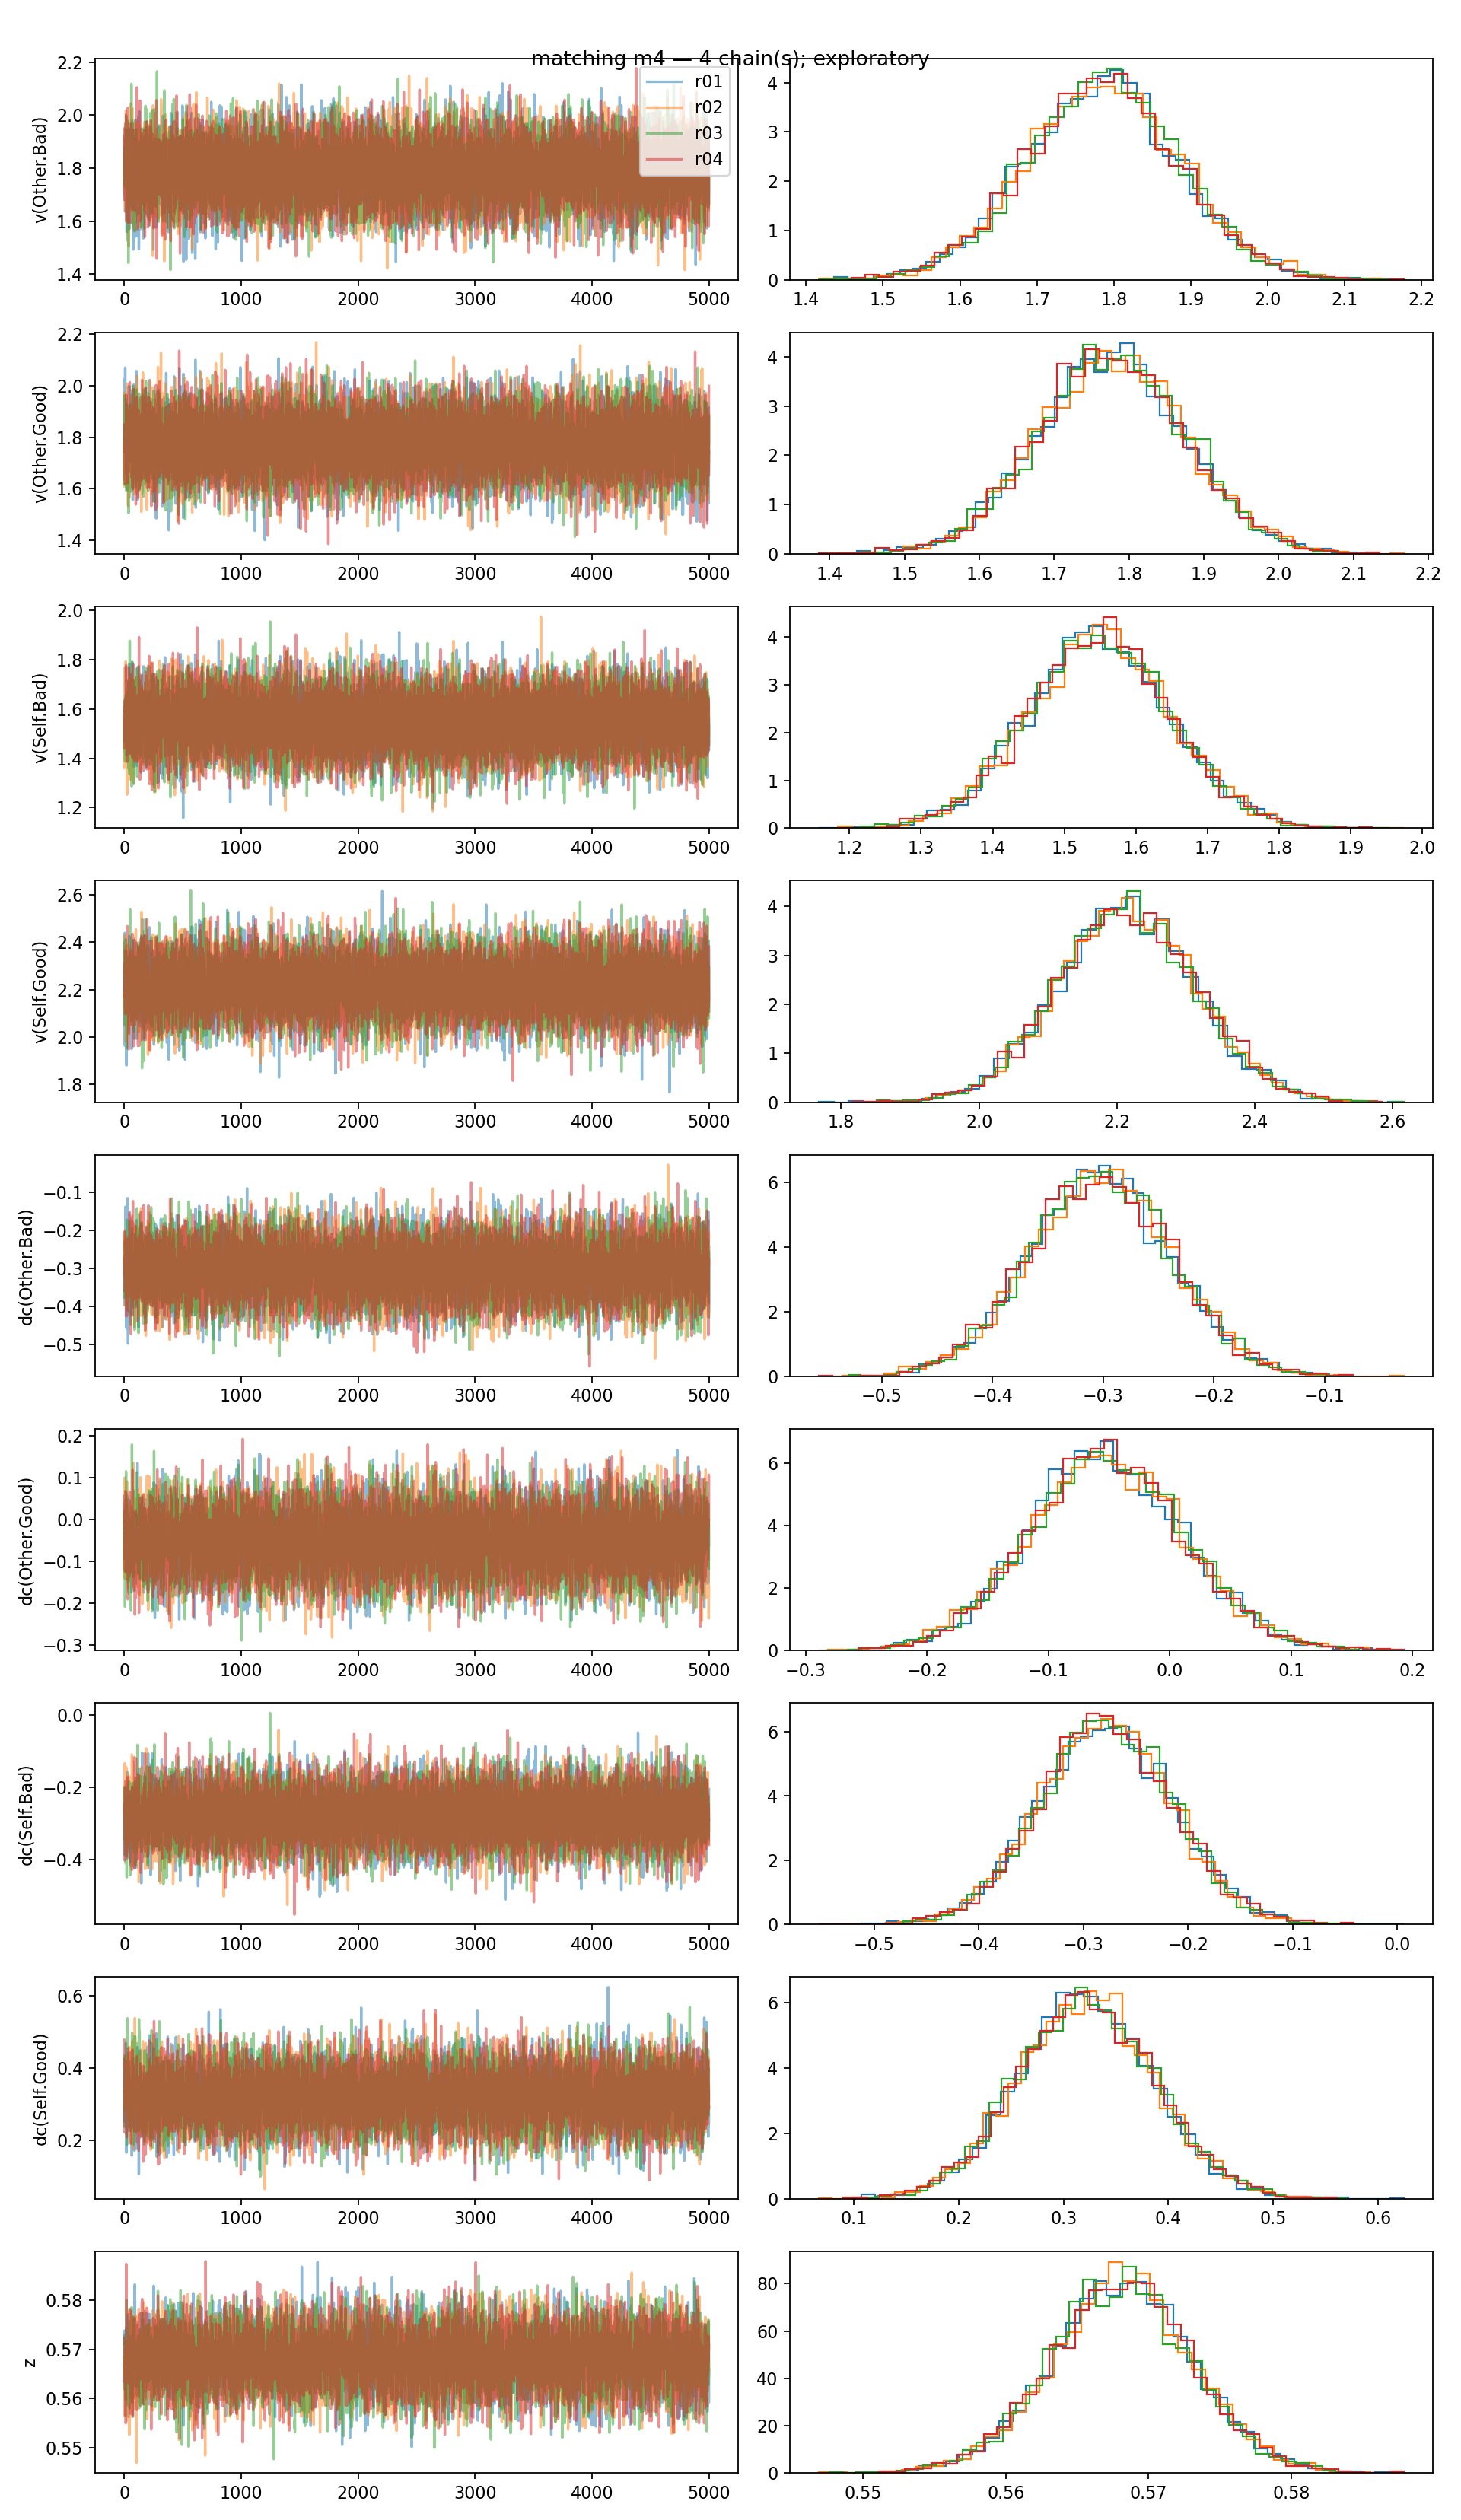

In [16]:
display(Image(filename=str(OUT / 'hddm/matching/figures/matching_m4_traces.png'), width=950))

**图 I-9. Matching的四链轨迹与参数分布。** 不同颜色表示不同链，左列为采样轨迹，右列为参数分布。

Identity和Valence未达到收敛标准，因此不解释其参数估计。对应诊断表和轨迹保存在各任务的结果目录。

### 历史探索 5. 模型对观测数据的预测

模型预测的慢反应时尾部比观测数据更长。实验有约0.9–1.2秒的反应窗口，而预测未施加相同窗口，两者的可比性受到限制。逐试次窗口尚未恢复，因此还不能判断窗口对差异的贡献。

图 I-10 比较DDM主体预测与两种补充离群生成约定。补充预测以.05概率生成随机选择，绝对RT分别在0–5或0–10秒内均匀分布。它们用于检查预测对设定的敏感性，与拟合时的完整离群似然并不严格一致。

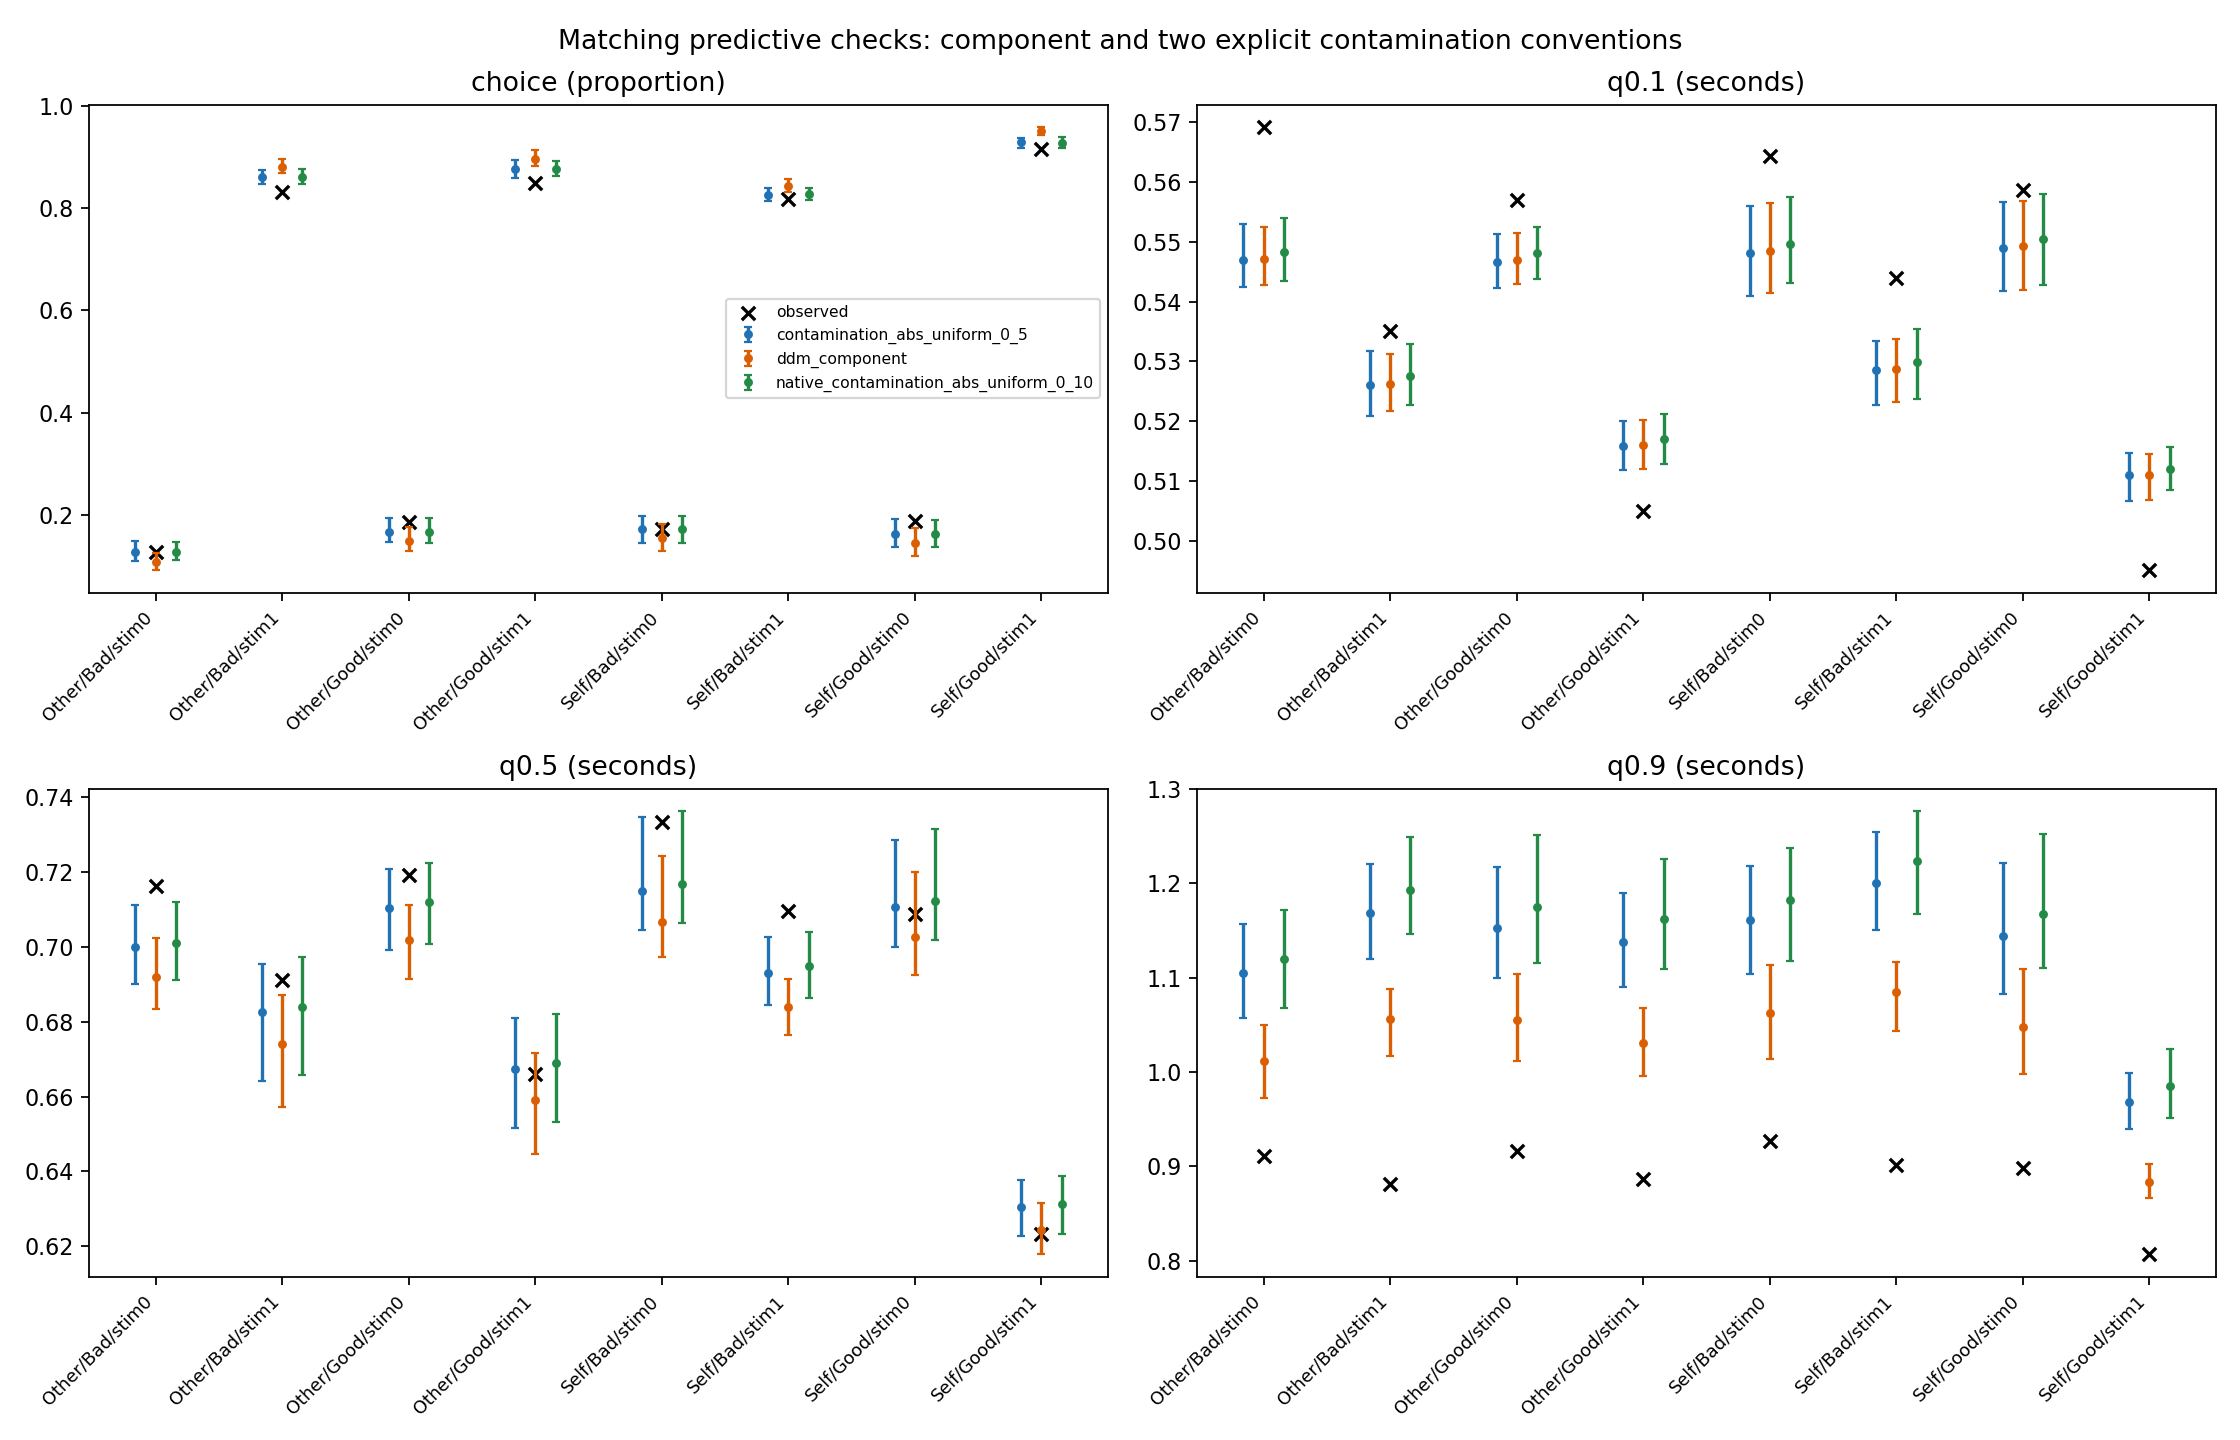

In [17]:
display(Image(filename=str(OUT / 'hddm/matching/figures/matching_m4_ppc.png'), width=950))

**图 I-10. Matching的观测数据与后验预测。** 黑色叉号为观测值；彩色点和区间表示预测均值及95%预测统计量区间。各面板分别显示选择比例及反应时分位数。

### 历史探索 6. 敏感性与参数恢复

### 排除极快反应

排除RT≤0.2秒后，以四条独立链重新拟合。主要群体估计变化很小，但个体参数`t_subj.7323`的tail ESS为342，未达到预设门槛。

In [18]:
sensitivity = read_json('hddm/matching/sensitivity/m4/diagnostics/review.json')
display(pd.DataFrame([{k:sensitivity[k] for k in ['max_rhat','min_bulk_ess','min_tail_ess','diagnostics_pass']}]))
changes = read_table('hddm/matching/sensitivity/m4/diagnostics/main_comparison.csv')
selected = ['z','v:Self.Good-Self.Bad','dc:Self.Good-Self.Bad']
display(changes.loc[changes.parameter.isin(selected), ['parameter','main_mean','sensitivity_mean','mean_shift']])

,max_rhat,min_bulk_ess,min_tail_ess,diagnostics_pass
0,1.0074,825.3142,342.4924,False


,parameter,main_mean,sensitivity_mean,mean_shift
8,z,0.5681,0.5681,-0.0000
9,v:Self.Good-Self.Bad,0.6663,0.6666,0.0003
14,dc:Self.Good-Self.Bad,0.6002,0.6026,0.0024


### 模拟数据中的参数恢复

设置无偏置、仅起点偏置、仅漂移偏置和两类偏置方向相反四种情景。每种情景生成一个数据集，包含12名模拟被试、每刺激方向每条件60试次；每种情景运行四链6000次，舍弃前3000次。离群反应采用0–5秒均匀分布。

四情景均存在收敛不足，尚不能确认参数恢复表现。每情景只有一个模拟数据集，也不足以评估反复抽样中的区间覆盖率。

In [19]:
recovery_rows = []
for scenario in ['neutral','z_only','dc_only','opposing']:
    d = read_table(f'hddm/matching/recovery/{scenario}/diagnostics.csv')
    passed = (d.r_hat < 1.01) & (d.ess_bulk >= 400) & (d.ess_tail >= 400)
    recovery_rows.append(dict(scenario=scenario,max_rhat=d.r_hat.max(),min_bulk_ess=d.ess_bulk.min(),min_tail_ess=d.ess_tail.min(),failed_parameters=int((~passed).sum())))
display(pd.DataFrame(recovery_rows))

,scenario,max_rhat,min_bulk_ess,min_tail_ess,failed_parameters
0,neutral,1.0764,75.8651,64.7867,39
1,z_only,1.0360,53.6740,58.8070,31
2,dc_only,1.1164,23.3371,23.8128,116
3,opposing,1.0999,31.4209,20.1324,133


### 历史探索 7. 讨论

Matching中的证据积累差异与Good-self加工优势的方向一致：Good-self高于Bad-self和Good-other，自我条件的道德属性差异也大于他人条件。但模型对慢RT的预测仍有偏差，参数恢复表现尚未得到确认，因此这些结果仍需谨慎解释。

本次模型让匹配与不匹配刺激共享v幅度，并令t跨条件共享；2020模型的v与t随匹配性、身份和道德属性变化。本次还增加了dc并改变离群设定。两者估计的参数含义不完全相同，数值不宜直接比较。Identity与Valence未收敛，也不足以评价原文的跨任务结论。

## 方法补充与复现

模型采用HDDMStimCoding，`split_param="v"`；有符号漂移为`(2*stim-1)*v+dc`。z_trans经逆logit转换。a表示边界间距，t对应原文的非决策时间t₀。Identity的v在Self/Other方向间共享，Valence的v在Good/Bad方向间共享，因此二者不提供四个独立条件的v估计。dc是本次扩展参数，也可能吸收刺激难度的不对称。

计算使用任务配置记录的固定dockerHDDM镜像。历史扩展的数据、脚本和输出仍位于仓库的 `02_reanalysis_2026/` 下；路径按该目录解释。本Notebook只读取保存的结果。完整运行命令见[第一部分 README](README_zh.md)，逐文件生成入口见`Scripts/hddm/output_manifest.json`。后处理已使用历史样本验证；整理后的完整拟合流程尚未从零重跑。数据库与逐次样本不随仓库分发。

[Hu等（2020）](https://doi.org/10.1525/collabra.301)；[Pan等（2025），dockerHDDM](https://doi.org/10.1177/25152459241298700)；[刺激编码方法代码](https://github.com/Chuan-Peng-Lab/ddm_stim_coding_posts)，commit `468965c8d4c991bb7633f3f38257a6bac978bce5`。

## 总结：已复现的现象 → 尚未识别的机制

选定行为结果支持 Good-self 优势；原论文 HDDM 复现与历史 M0–M4 扩展都有明确的诊断和覆盖边界。M0–M4 的慢RT预测、跨任务收敛和恢复问题促使我们在第二部分重新处理超时、关系难度和观察过程，而不是直接依据参数差宣布唯一机制。

继续阅读[第二部分总 Notebook](../02_reanalysis_2026/02_reanalysis_2026.ipynb)。第二部分五折预测比较尚未可靠完成，第三部分尚未正式分析。
